# Random Number Generator Analysis
Comparison of Linux /dev/urandom, OpenSSL rand, and Windows .NET RandomNumberGenerator. Each input file should contain 1 MiB.

In [8]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, binomtest

files = {
    "Linux urandom": "linux_urandom.bin",
    "OpenSSL": "openssl_rand.bin",
    "Windows CNG": "windows_cng.bin"
}

data_dir = Path("../data")
samples = {}

for name, filename in files.items():
    path = data_dir / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run the generator scripts first.")
    samples[name] = np.fromfile(path, dtype=np.uint8)
    print(name, len(samples[name]), "bytes")
    assert len(samples[name]) == 1048576


Linux urandom 1048576 bytes
OpenSSL 1048576 bytes
Windows CNG 1048576 bytes


## Byte frequency distribution

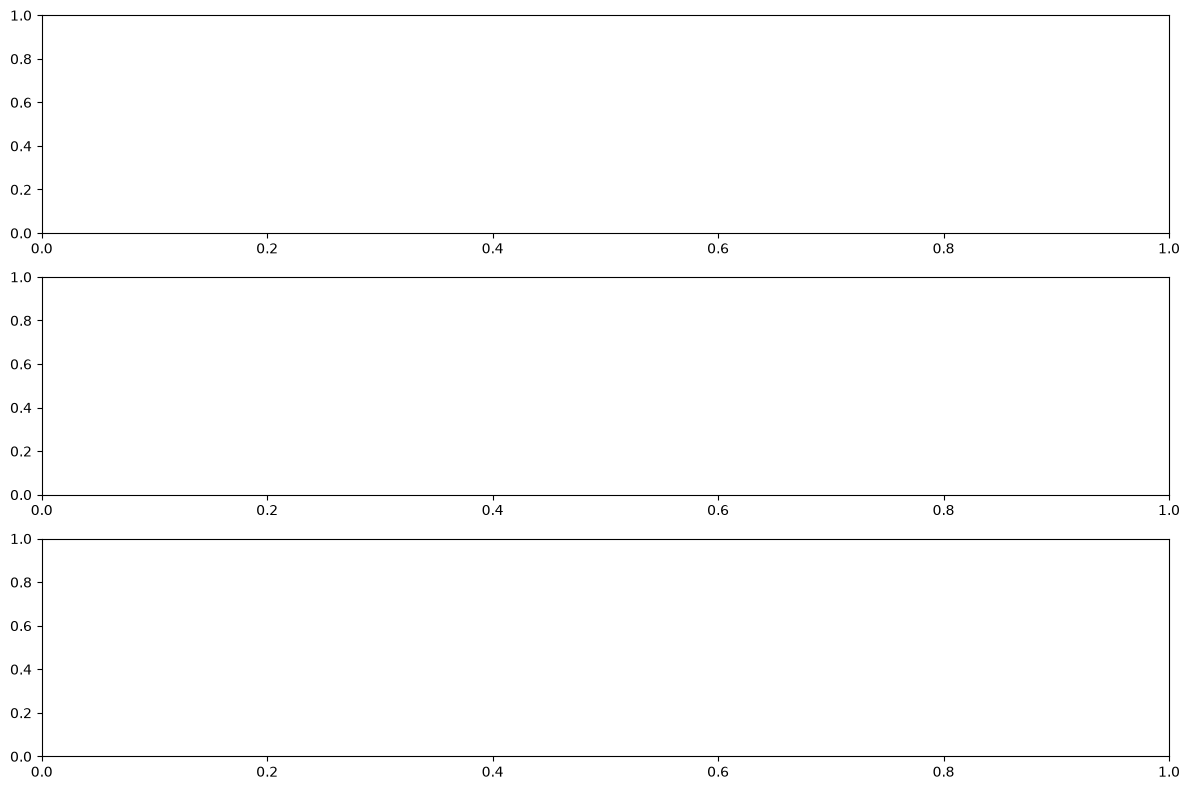

""


In [4]:

rows = []

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

for ax, (name, data) in zip(axes, samples.items()):
    counts = np.bincount(data, minlength=256)
    chi, p = chisquare(counts)
    rows.append({
        "Generator": name,
        "Chi-square": chi,
        "Chi-square p-value": p,
        "Minimum frequency": counts.min(),
        "Maximum frequency": counts.max()
    })
    ax.bar(range(256), counts)
    ax.set_title(name)
    ax.set_xlabel("Byte value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))


## Bit balance

In [9]:

rows = []

for name, data in samples.items():
    ones = int(np.unpackbits(data).sum())
    total = len(data) * 8
    result = binomtest(ones, total, 0.5)
    rows.append({
        "Generator": name,
        "Zero bits": total - ones,
        "One bits": ones,
        "One-bit percentage": ones * 100 / total,
        "P-value": result.pvalue
    })

display(pd.DataFrame(rows))


,Generator,Zero bits,One bits,One-bit percentage,P-value
0,Linux urandom,4193809,4194799,50.005901,0.732751
1,OpenSSL,4193627,4194981,50.008070,0.640395
2,Windows CNG,4192945,4195663,50.016201,0.348198


## Repeated patterns and correlation

In [10]:

rows = []

for name, data in samples.items():
    equal_adjacent = int(np.sum(data[1:] == data[:-1]))
    blocks = data[:len(data) // 16 * 16].reshape(-1, 16)
    _, counts = np.unique(blocks, axis=0, return_counts=True)
    duplicate_blocks = int(np.sum(counts - 1))
    correlation = np.corrcoef(
        data[:-1].astype(float), data[1:].astype(float)
    )[0, 1]

    rows.append({
        "Generator": name,
        "Equal adjacent bytes": equal_adjacent,
        "Duplicate aligned 16-byte blocks": duplicate_blocks,
        "Lag-1 correlation": correlation
    })

display(pd.DataFrame(rows))


,Generator,Equal adjacent bytes,Duplicate aligned 16-byte blocks,Lag-1 correlation
0,Linux urandom,4076,0,0.000979
1,OpenSSL,4119,0,0.000003
2,Windows CNG,4185,0,0.000282


## Conclusion
Frequency, bit balance, repeated-block and correlation checks can reveal some statistical anomalies. Passing these tests does not prove cryptographic security. Security depends on the generator design, operating system, entropy sources and implementation.